In [53]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp 
from IPython.display import display

In [ ]:
t = sp.symbols("t")
x = sp.Function("x")
y = sp.Function("y") 

(True, [0, 0])


Eq(x(t), exp(-t/4)*cos(t))

Eq(y(t), -exp(-t/4)*sin(t))

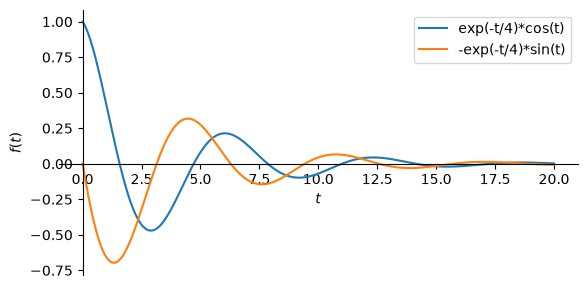

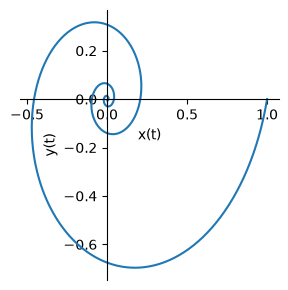

In [63]:
eqs =[ sp.Eq(x(t).diff(t), - x(t)/4 + y(t)), sp.Eq(y(t).diff(t), -x(t) - y(t)/ 4)]
solsp = sp.dsolve(eqs, ics={ x(0): 1, y(0): 0})
print(sp.checkodesol(eqs, solsp))
display(solsp[0], solsp[1])

sp.plot(solsp[0].rhs, solsp[1].rhs, (t, 0, 20), labels=["x(t)", "y(t)"], legend= True, size=(6,3));
sp.plot_parametric((solsp[0].rhs, solsp[1].rhs, (t, 0, 20)), xlabel="x(t)", ylabel="y(t)", size=(3,3));


In [65]:
def fxfy(t, u):
    x, y = u
    dxdt = - x / 4. + y
    dydt = - x - y/ 4.
    return [dxdt, dydt]

solnp = solve_ivp(fxfy, (0,20), [1,0], t_eval=np.linspace(0,20,100), rtol =1e-10, atol=1e-11)
print(solnp.success)

True


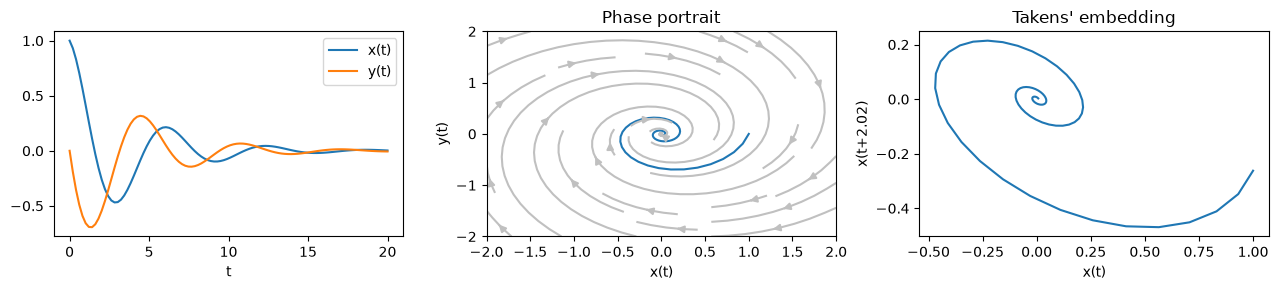

In [77]:
fig,ax = plt.subplots(1,3, figsize=(13,3))

ax[0].plot(solnp.t, solnp.y[0], label="x(t)")
ax[0].plot(solnp.t, solnp.y[1], label="y(t)")
ax[0].set_xlabel("t")
ax[0].legend()

ax[1].plot(solnp.y[0], solnp.y[1], label="trajectory")
ax[1].set_xlabel("x(t)")
ax[1].set_ylabel("y(t)")

xs = np.linspace(-2,2, 100)
X,Y = np.meshgrid(xs,xs)
U, V = fxfy(0, [X,Y])
ax[1].streamplot(X,Y, U,V, density=0.5, color="silver")
ax[1].set_title("Phase portrait")

k=10
tau = k*(solnp.t[1] - solnp.t[0])
ax[2].plot(solnp.y[0, :-k], solnp.y[0,k:])
ax[2].set_xlabel("x(t)")
ax[2].set_ylabel(f"x(t+{tau:.2f})")
ax[2].set_title("Takens' embedding")


plt.tight_layout()
plt.show()